# Walkthrough: attrition was a promotion problem

This notebook runs the whole analysis step by step on the synthetic records in `data/synthetic/`. Each step says what it does and why. Run it top to bottom with `jupyter lab notebooks/walkthrough.ipynb` from the repo folder.

The records are made up. They are modeled on the layout of a bank's HR files, and the team leader effect is a setting in `ael/generate.py`.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from ael import contract, view, analyze
pd.set_option("display.width", 120)

## 1. Five files, five owners

Roster, KPI and warning stage, probation, resignation list, exit form. In a company each comes from a different team on its own schedule.

In [2]:
t = view.load(Path("data/synthetic"))
pd.DataFrame({name: [len(df), ", ".join(df.columns)] for name, df in t.items()}, index=["rows", "columns"]).T

,rows,columns
roster_monthly,163006,"month, employee_id, job_title, center_code, br..."
kpi_monthly,163006,"month, employee_id, kpi_achievement_pct, kpi_r..."
probation,6648,"employee_id, join_date, probation_result"
resignations,8553,"employee_id, job_title, exit_date, center_code..."
exit_interviews,3440,"submitted_date, employee_id, exit_date, reason..."


## 2. Check the files before joining them

The contract says what every column must look like and how the files link. Anything broken stops here instead of turning into a wrong number later.

In [3]:
problems = contract.check(Path("data/synthetic"))
print("All files pass the contract." if not problems else "\n".join(problems))

All files pass the contract.


## 3. Build one seller-month view

No file says who reports to whom, and none records promotions. So:
- a seller's leader is the Team Leader on the same center code that month
- a leader's route comes from their own job-title history: a Sales Officer in the top fifth of their branch before becoming Team Leader is a "top seller"
- an exit is someone missing from next month's roster

In [4]:
s, routes, gaps = view.seller_months(t)
print(f"{len(s):,} seller-months, {s.employee_id.nunique():,} sellers, {s.center_code.nunique()} teams")
routes.route.value_counts()

72,644 seller-months, 7,189 sellers, 300 teams


route
unknown           361
top seller        342
average seller    172
Name: count, dtype: int64

In [5]:
s.head()

,month,employee_id,center_code,branch_code,region,leader_id,route,team_size,team_size_band,tenure_months,tenure_band,kpi_achievement_pct,kpi_rating,warning_stage,left,exit_type,recorded,incomplete
0,2022-01,E100002,C060,B00,R01,E100680,top seller,9,9-10,43,25+,113.0,B,None,0,NaN,False,False
1,2022-01,E100004,C000,B00,R01,E103971,unknown,8,8 or fewer,58,25+,85.5,C,None,0,NaN,False,False
2,2022-01,E100006,C000,B00,R01,E103971,unknown,8,8 or fewer,26,25+,105.6,B,None,0,NaN,False,False
3,2022-01,E100011,C001,B01,R02,E100009,unknown,9,9-10,28,25+,83.2,D,None,0,NaN,False,False
4,2022-01,E100012,C001,B01,R02,E100009,unknown,9,9-10,57,25+,88.0,C,None,0,NaN,False,False


## 4. The quick read: by region

This is where most turnover reviews stop. It points at locations.

In [6]:
regions = analyze.region_rates(s)
regions

,region,seller_months,exits,exits_per_100_per_year,share_under_top_seller_leaders
0,R01,8412,569,81.2,0.604
1,R06,8633,566,78.7,0.523
2,R08,7335,445,72.8,0.360
3,R07,6947,420,72.5,0.435
4,R03,8532,478,67.2,0.603
5,R05,8216,431,63.0,0.350
6,R02,8754,415,56.9,0.450
7,R09,7204,330,55.0,0.396
8,R04,8309,375,54.2,0.485


Location and leadership overlap: the branches that lose the most people also have more teams under top-seller leaders. The next steps pull them apart.

## 5. Exits by the leader's promotion route, raw

In [7]:
analyze.raw_rates(s)

,route,seller_months,exits,exits_per_100_per_year
0,average seller,15888,654,49.4
1,top seller,34100,2242,78.9
2,unknown,22354,1133,60.8


## 6. Does the gap hold after controls?

A logistic model on seller-months with branch, tenure, team size and month. Standard errors are clustered by team, because sellers on one team share a leader. KPI stays out on purpose: a poor leader can drag KPI down before people quit, so controlling for it would hide part of the effect.

In [8]:
ctrl = analyze.controlled(s)
ctrl

{'rows': 49988,
 'teams': 243,
 'rate_top': np.float64(76.5),
 'rate_average': np.float64(53.1),
 'gap': np.float64(23.3),
 'gap_ci': [18.3, 29.2],
 'odds_ratio': 1.47,
 'odds_ratio_ci': [1.33, 1.63]}

The gap shrinks once branch is in, because busy branches promote top sellers more often. It does not go away.

## 7. How fast new hires leave

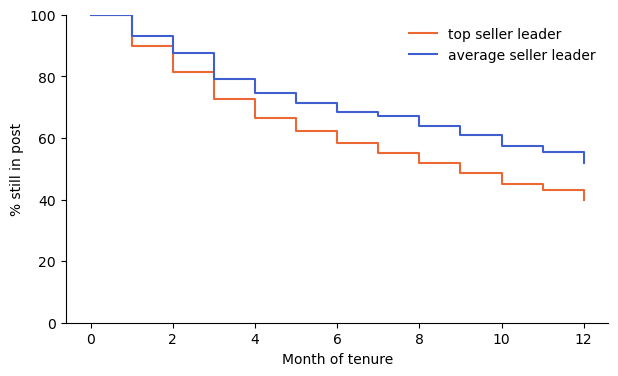

In [9]:
surv = analyze.survival(s)
fig, ax = plt.subplots(figsize=(7, 4))
for route, color in [("top seller", "#eb6834"), ("average seller", "#3f5fd0")]:
    d = surv[surv.route == route]
    ax.step(d.tenure_month, d.still_in_post * 100, where="post", color=color, label=f"{route} leader")
ax.set_xlabel("Month of tenure"); ax.set_ylabel("% still in post"); ax.set_ylim(0, 100); ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 8. What the exit form says

Fewer than half of leavers fill in the form, and few tick "Leadership". Read on its own, the form clears the leaders.

In [10]:
analyze.reasons(s, t["exit_interviews"]).pivot(index="reason", columns="route", values="share")

route,average seller,top seller
reason,,
Career path,0.356,0.303
Leadership,0.083,0.127
Personal growth,0.375,0.365
Unsupportive scope of work,0.186,0.205


## 9. What doing nothing costs, in sales

Each extra exit is 1 month with the seat empty plus 3 months at half output while the new hire ramps up. These are assumptions in `analyze.COST`.

In [11]:
analyze.cost(ctrl, s)

{'assumptions': {'vacancy_months': 1.0,
  'ramp_months': 3,
  'ramp_output_share': 0.5},
 'seller_years_under_top_seller_leaders_per_year': 1421,
 'extra_exits_per_year': 331,
 'sales_months_lost_per_exit': 2.5,
 'full_time_sellers_of_sales_lost_per_year': 69}

## 10. Checks

Months held out because the resignation list runs late, and whether the answer moves when a rule changes.

In [12]:
gaps[gaps.incomplete]

,region,month,roster_exits,unrecorded,unrecorded_share,incomplete
213,R07,2023-12,20,20,1.0,True


In [13]:
pd.DataFrame(analyze.sensitivity(t, s))

,check,rate_top,rate_average,gap,gap_ci
0,Voluntary resignations only,74.2,51.0,23.2,"[17.5, 29.1]"
1,Leave out each seller's first 3 months,67.4,46.1,21.4,"[15.7, 28.0]"
2,Top seller = top 30% instead of top 20%,75.5,52.2,23.3,"[17.5, 29.3]"


The no-effect check lives in `scripts/null_calibration.py`. It generates 20 datasets with the leader effect switched off and runs these same steps on each. Its summary is in `docs/null_calibration.json`.

In [14]:
import json
{k: v for k, v in json.loads(Path("docs/null_calibration.json").read_text()).items() if k != "detail"}

{'runs': 20,
 'leader_effect': 1.0,
 'mean_gap': -0.4,
 'intervals_including_zero': 18}